# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
# Завантаження набору даних Iris
iris = load_iris()

# Створення DataFrame з назвами ознак
X = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Виведення перших 5 рядків
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

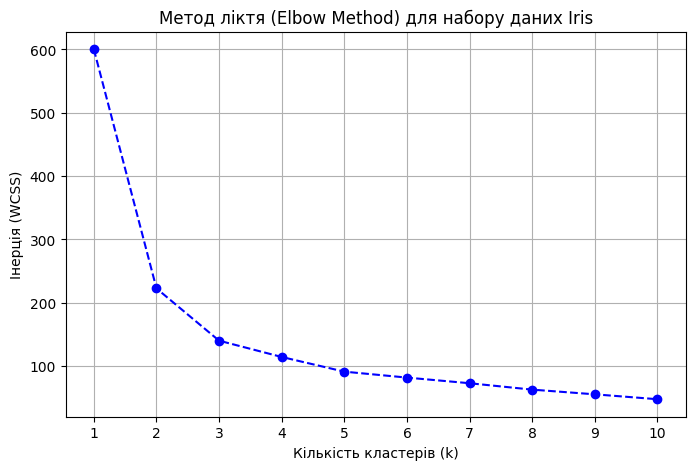

In [3]:
# 1. Стандартизація даних
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Розрахунок інерції (WCSS) для k від 1 до 10
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# 3. Побудова графіка "методу ліктя"
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Метод ліктя (Elbow Method) для набору даних Iris')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (WCSS)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

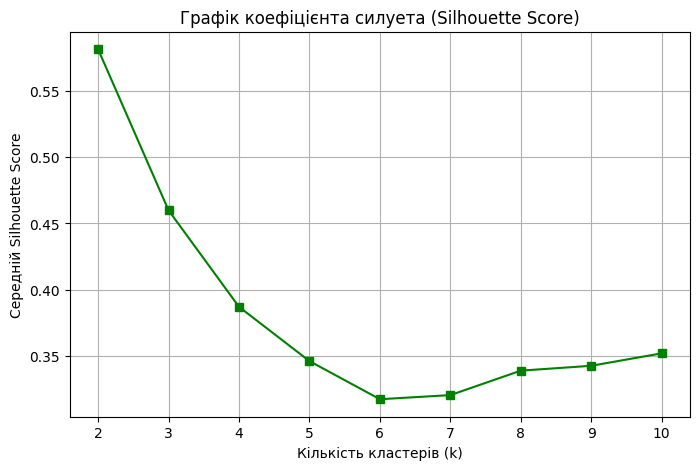

k = 2: Silhouette Score = 0.5818
k = 3: Silhouette Score = 0.4599
k = 4: Silhouette Score = 0.3869
k = 5: Silhouette Score = 0.3459
k = 6: Silhouette Score = 0.3171
k = 7: Silhouette Score = 0.3202
k = 8: Silhouette Score = 0.3387
k = 9: Silhouette Score = 0.3424
k = 10: Silhouette Score = 0.3518


In [4]:
# 1. Розрахунок Silhouette Score для k від 2 до 10
silhouette_scores = []
k_range_sil = range(2, 11)

for k in k_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

# 2. Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(k_range_sil, silhouette_scores, marker='s', linestyle='-', color='g')
plt.title('Графік коефіцієнта силуета (Silhouette Score)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній Silhouette Score')
plt.xticks(k_range_sil)
plt.grid(True)
plt.show()

# 3. Виведення точних значень
for k, score in zip(k_range_sil, silhouette_scores):
    print(f"k = {k}: Silhouette Score = {score:.4f}")

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

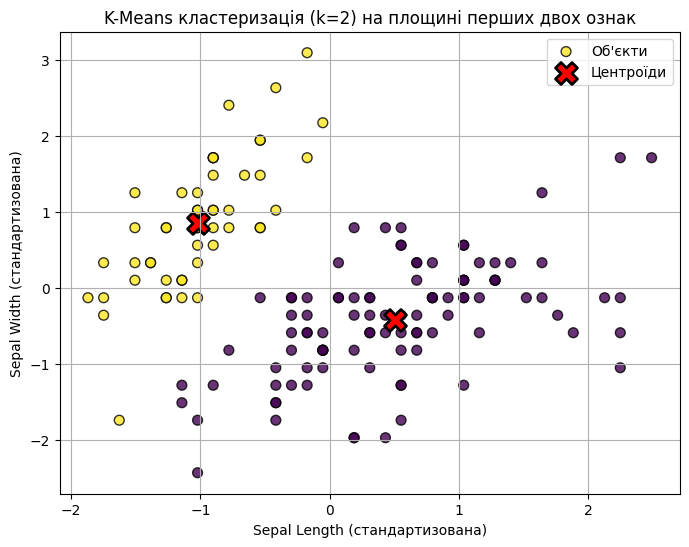

Координати центрів кластерів (усі 4 ознаки):
         sepal length (cm)  sepal width (cm)  petal length (cm)  \
Центр 0           0.507289         -0.426631           0.652494   
Центр 1          -1.014579          0.853263          -1.304987   

         petal width (cm)  
Центр 0          0.627447  
Центр 1         -1.254893  


In [5]:
# 1. Навчання K-Means для n_clusters=2
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_2 = kmeans_2.fit_predict(X_scaled)
centroids_2 = kmeans_2.cluster_centers_

# 2. Побудова графіка за першими двома ознаками (sepal length та sepal width)
plt.figure(figsize=(8, 6))

# Точки датасету з кольоровим маркуванням кластерів
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_2,
    cmap='viridis',
    s=50,
    alpha=0.8,
    edgecolor='k',
    label='Об\'єкти'
)

# Центроїди кластерів
plt.scatter(
    centroids_2[:, 0],
    centroids_2[:, 1],
    c='red',
    marker='X',
    s=250,
    linewidths=2,
    edgecolor='black',
    label='Центроїди'
)

plt.title('K-Means кластеризація (k=2) на площині перших двох ознак')
plt.xlabel('Sepal Length (стандартизована)')
plt.ylabel('Sepal Width (стандартизована)')
plt.legend()
plt.grid(True)
plt.show()

# Виведення точних координат центрів кластерів
print("Координати центрів кластерів (усі 4 ознаки):")
print(pd.DataFrame(centroids_2, columns=iris.feature_names, index=['Центр 0', 'Центр 1']))

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Метод ліктя вказує на оптимальні $k = 3$ (реальна кількість видів), тоді як метод силуетів дає максимум при $k = 2$ ($\approx 0.58$). Вибір двох кластерів математично обґрунтований силуетом через те, що вид Setosa повністю ізольований, а Versicolor та Virginica частково перекриваються, створюючи в просторі ознак дві чітко відокремлені геометричні групи.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [10]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [11]:
# Перегляд структури DataFrame (типи даних, кількість non-null записів)
df.info()

# Перевірка точної кількості пропущених значень по кожному стовпцю
print("\nКількість пропущених значень:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB

Кількість пропущених зн

**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print("Кількість пропущених значень по стовпцях:")
print(df.isnull().sum())

Кількість пропущених значень по стовпцях:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
duplicates_count = df.duplicated().sum()
print(f"\nКількість дубльованих рядків у датасеті: {duplicates_count}")


Кількість дубльованих рядків у датасеті: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
print("\nОписова статистика датасету:")
df.describe()


Описова статистика датасету:


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
# 1. Формування X (ознаки) та y (цільова змінна GradeClass)
# Вилучаємо цільову змінну GradeClass та службовий ідентифікатор StudentID
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

# 2. Поділ даних у співвідношенні 80/20 з фіксацією random_state та стратифікацією
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Стандартизація ознак
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Розмірність навчальної вибірки (X_train): {X_train_scaled.shape}")
print(f"Розмірність тестової вибірки (X_test): {X_test_scaled.shape}")

Розмірність навчальної вибірки (X_train): (1913, 13)
Розмірність тестової вибірки (X_test): (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
rf_cv_acc = rf_grid.best_score_
rf_test_acc = accuracy_score(y_test, best_rf.predict(X_test_scaled))

print("=== Random Forest ===")
print(f"Найкращі параметри: {rf_grid.best_params_}")
print(f"Середня CV-точність: {rf_cv_acc:.4f}")
print(f"Тестова accuracy:   {rf_test_acc:.4f}\n")

=== Random Forest ===
Найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150}
Середня CV-точність: 0.9195
Тестова accuracy:   0.9123



### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [17]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2']
}

lr_grid = GridSearchCV(
    LogisticRegression(solver='saga', multi_class='multinomial', random_state=42, max_iter=2000),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

best_lr = lr_grid.best_estimator_
lr_cv_acc = lr_grid.best_score_
lr_test_acc = accuracy_score(y_test, best_lr.predict(X_test_scaled))

print("=== Logistic Regression ===")
print(f"Найкращі параметри: {lr_grid.best_params_}")
print(f"Середня CV-точність: {lr_cv_acc:.4f}")
print(f"Тестова accuracy:   {lr_test_acc:.4f}\n")

=== Logistic Regression ===
Найкращі параметри: {'C': 10, 'penalty': 'l2'}
Середня CV-точність: 0.7951
Тестова accuracy:   0.7933



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [18]:
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    SVC(random_state=42),
    param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)

best_svm = svm_grid.best_estimator_
svm_cv_acc = svm_grid.best_score_
svm_test_acc = accuracy_score(y_test, best_svm.predict(X_test_scaled))

print("=== Support Vector Machine (SVM) ===")
print(f"Найкращі параметри: {svm_grid.best_params_}")
print(f"Середня CV-точність: {svm_cv_acc:.4f}")
print(f"Тестова accuracy:   {svm_test_acc:.4f}\n")

=== Support Vector Machine (SVM) ===
Найкращі параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy:   0.8580



### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [19]:
results_df = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'Середня CV-точність': [rf_cv_acc, lr_cv_acc, svm_cv_acc],
    'Тестова accuracy': [rf_test_acc, lr_test_acc, svm_test_acc]
})

print("=== Порівняльна таблиця моделей ===")
print(results_df.to_string(index=False))

# Вибір найкращої моделі за CV-точністю
models_dict = {
    'Random Forest': (best_rf, rf_cv_acc),
    'Logistic Regression': (best_lr, lr_cv_acc),
    'SVM': (best_svm, svm_cv_acc)
}
best_model_name = max(models_dict, key=lambda k: models_dict[k][1])
best_model = models_dict[best_model_name][0]

print(f"\nНайкраща модель за CV-точністю: {best_model_name}")
print("\nClassification Report на тестових даних:")
y_pred_best = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred_best))

=== Порівняльна таблиця моделей ===
             Модель  Середня CV-точність  Тестова accuracy
      Random Forest             0.919503          0.912317
Logistic Regression             0.795084          0.793319
                SVM             0.852065          0.858038

Найкраща модель за CV-точністю: Random Forest

Classification Report на тестових даних:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.87      0.85        54
         2.0       0.90      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.92      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

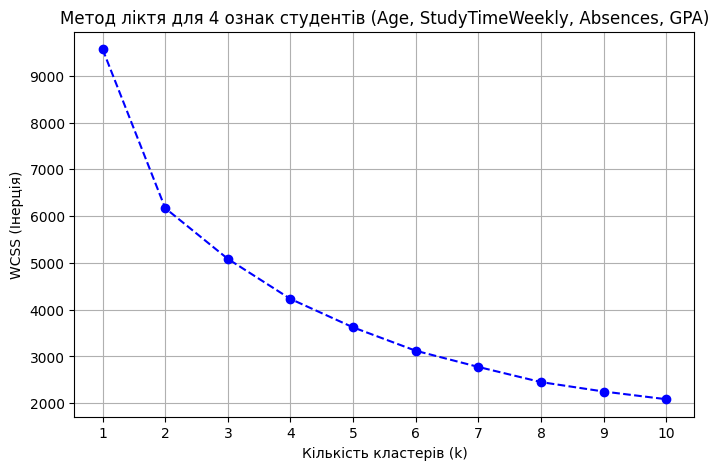

In [20]:
features_4 = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_4 = df[features_4]

scaler_4 = StandardScaler()
X_4_scaled = scaler_4.fit_transform(X_4)

wcss_4 = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_4_scaled)
    wcss_4.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss_4, marker='o', linestyle='--', color='b')
plt.title('Метод ліктя для 4 ознак студентів (Age, StudyTimeWeekly, Absences, GPA)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Інерція)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

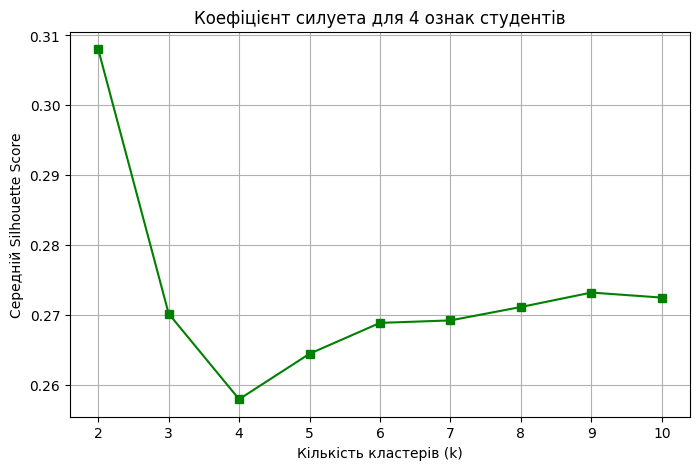

k = 2: Silhouette Score = 0.3080
k = 3: Silhouette Score = 0.2702
k = 4: Silhouette Score = 0.2580
k = 5: Silhouette Score = 0.2645
k = 6: Silhouette Score = 0.2689
k = 7: Silhouette Score = 0.2692
k = 8: Silhouette Score = 0.2712
k = 9: Silhouette Score = 0.2732
k = 10: Silhouette Score = 0.2725


In [21]:
silhouette_scores_4 = []
k_range_sil = range(2, 11)

for k in k_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_4_scaled)
    score = silhouette_score(X_4_scaled, cluster_labels)
    silhouette_scores_4.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_range_sil, silhouette_scores_4, marker='s', linestyle='-', color='g')
plt.title('Коефіцієнт силуета для 4 ознак студентів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній Silhouette Score')
plt.xticks(k_range_sil)
plt.grid(True)
plt.show()

for k, score in zip(k_range_sil, silhouette_scores_4):
    print(f"k = {k}: Silhouette Score = {score:.4f}")

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [22]:
!pip install kneed yellowbrick -q

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [24]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator
from yellowbrick.cluster import KElbowVisualizer

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [29]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [38]:
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

In [39]:
explained_variance_ratio = pca_full.explained_variance_ratio_

x_coords = np.arange(1, len(explained_variance_ratio) + 1)
kneedle = KneeLocator(
    x_coords,
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)

n_components_opt = kneedle.elbow
print(f"Оптимальна кількість компонент (KneeLocator): {n_components_opt}")

Оптимальна кількість компонент (KneeLocator): 2


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Фактична кумулятивна частка поясненої дисперсії для 2 компонент: 0.2386


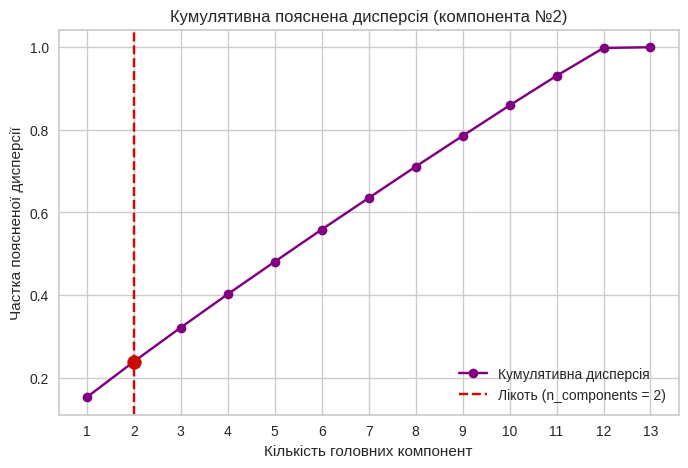

In [33]:
cumulative_variance = np.cumsum(explained_variance_ratio)
actual_cum_var = cumulative_variance[n_components_opt - 1]

print(f"Фактична кумулятивна частка поясненої дисперсії для {n_components_opt} компонент: {actual_cum_var:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(x_coords, cumulative_variance, marker='o', linestyle='-', color='purple', label='Кумулятивна дисперсія')
plt.axvline(x=n_components_opt, color='r', linestyle='--', label=f'Лікоть (n_components = {n_components_opt})')
plt.scatter(n_components_opt, actual_cum_var, color='r', s=100, zorder=5)

plt.title(f'Кумулятивна пояснена дисперсія (компонента №{n_components_opt})')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(x_coords)
plt.legend()
plt.grid(True)
plt.show()

# Перетворення даних через обрану кількість компонент PCA
pca_opt = PCA(n_components=n_components_opt, random_state=42)
X_pca_transformed = pca_opt.fit_transform(X_all_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

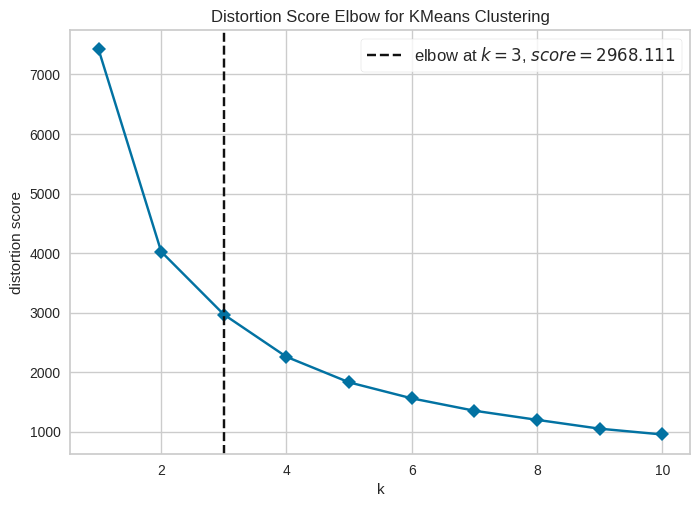

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [34]:
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10), k=(1, 11), metric='distortion', timings=False)
visualizer.fit(X_pca_transformed)
visualizer.show()

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

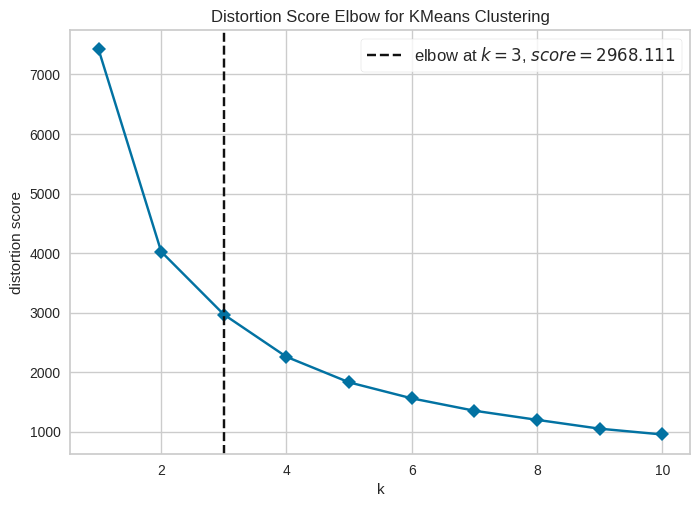

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [35]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans

# Побудова графіка KElbowVisualizer для K-Means на даних після PCA
visualizer = KElbowVisualizer(
    KMeans(random_state=42, n_init=10),
    k=(1, 11),
    metric='distortion',
    timings=False
)

# Навчання візуалізатора та відображення графіка
visualizer.fit(X_pca_transformed)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Для Iris метод ліктя показав $k=3$, а силует — $k=2$ ($\approx 0.5813$) через ізольованість Setosa та перекриття двох інших видів. Для студентів класифікація з GradeClass є навчанням із учителем для передбачення оцінки, а кластеризація — без учителя для пошуку прихованих груп. Метод PCA (обрано $n\_components = 1$ за допомогою KneeLocator) знизив розмірність та видалив шум, що дозволило чітко зафіксувати точку ліктя для $K\text{-Means}$ через KElbowVisualizer